### Load data
1. **Pandas** loads and cleans raw dataset files into a clean DataFrame
2. **NumPy** converts or processes feature columns into numerical arrays suitable for linear algebra
3. **Scikit-Learn (linear_model)** takes those matrices, fits a predictive mathematical model, and generates output predictions

In [1]:
import numpy as np
import pandas as pd

file_name = "Titanic-Dataset.csv"
df = pd.read_csv(file_name)

### Shape of the dataset

In [2]:
df.shape

(891, 12)

### Plot data

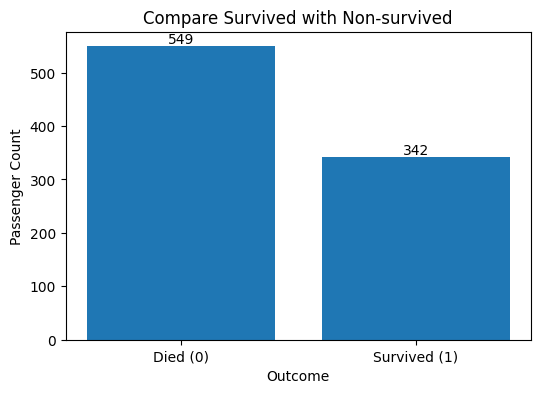

In [3]:
import matplotlib.pyplot as plt 

counts = df["Survived"].value_counts()

plt.figure(figsize=(6, 4))

# Survived versus Non-survived
bars = plt.bar(
    ["Died (0)", "Survived (1)"], 
    [counts[0], counts[1]],
)

for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2, 
        yval + 5, 
        f"{yval}", 
        ha="center"
    )

plt.title("Compare Survived with Non-survived")
plt.xlabel("Outcome")
plt.ylabel("Passenger Count")

plt.show()

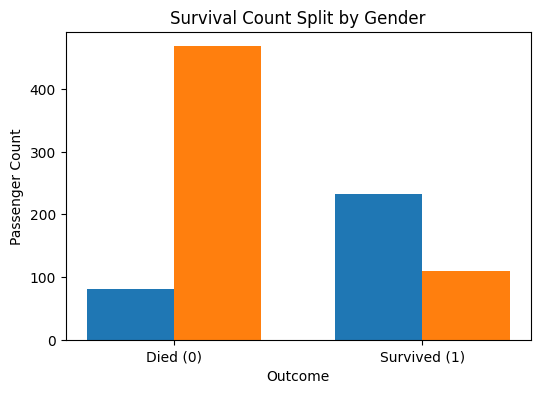

In [4]:
# Group data by Survived status and Sex
grouped = df.groupby(["Survived", "Sex"]).size().unstack()
# (0, female), (0, male), (1, female), (1, male)

x = np.arange(2)  # 2 columns per group
width = 0.35

plt.figure(figsize=(6, 4))
plt.bar(x - width/2, grouped["female"], width, label="Female")
plt.bar(x + width/2, grouped["male"], width, label="Male")

plt.xticks(x, ["Died (0)", "Survived (1)"])
plt.title("Survival Count Split by Gender")
plt.xlabel("Outcome")
plt.ylabel("Passenger Count")

plt.show()

### Split data into test and train datasets

In [5]:
from sklearn.model_selection import train_test_split

# Copy to a new df to avoid affecting the original df
df_clean = df[["Pclass", "Sex", "Age", "Fare", "Survived"]].copy()

# Convert 'Sex' string column to 0 (female) and 1 (male)
df_clean["Sex"] = (df_clean["Sex"] == "male").astype(int)

# Fill missing values
# Median: The middle value when the numbers are arranged in order from smallest to largest
df_clean["Age"] = df_clean["Age"].fillna(df_clean["Age"].median())
df_clean["Fare"] = df_clean["Fare"].fillna(df_clean["Fare"].median())

# 2. Extract X and y arrays
X = df_clean[["Pclass", "Sex", "Age", "Fare"]].values # 2D
y = df_clean["Survived"].values # 1D

# 3. Train-Test Split
x_train, x_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2, # 80% train, 20% test
    random_state=42, # Fixed random seed
    stratify=y # Preserves the survivor and died class distribution in both splits
)

# Check the shapes
print("x_train shape:", x_train.shape)
print("x_test shape:",  x_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:",  y_test.shape)

x_train shape: (712, 4)
x_test shape: (179, 4)
y_train shape: (712,)
y_test shape: (179,)


# Logistic Regression

### Train

$$\text{Loss}_{\text{total}} = \text{Loss}(\text{Predictions}, \text{Targets}) + \lambda \sum \text{Penalty}(w)$$

$$C = \frac{1}{\lambda}$$

L2 Regularization (Ridge) $\sum w_i^2$

L1 Regularization (Lasso) $\sum \Vert{}w_i\Vert{}$

In [6]:
from sklearn import linear_model

# C controls regularization strength
# C is the inverse of regularization strength
# Regularization adds a penalty to large feature weights to prevent overfitting and keep the model simple.
# Small C means heavy penalty

# solver='newton-cg' stands for Newton Conjugate Gradient, an optimization method used to find the global minimum of the loss function.

clf = linear_model.LogisticRegression(C=1e40, solver='newton-cg')
fitted_model = clf.fit(x_train, y_train)

### Evaluate

- True Positive (TP): Model correctly predicted positive
- True Negative (TN): Model correctly predicted negative
- False Positive (FP): Model incorrectly predicted positive
- False Negative (FN): Model incorrectly predicted negative

$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$

$$\text{Precision} = \frac{TP}{TP + FP}$$

$$\text{Recall} = \frac{TP}{TP + FN}$$

$$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

$$\text{Support} = \text{Actual Count} = TP + FN \quad \text{(for a specific class)}$$

$$\text{Macro Avg} = \frac{\text{Metric}_{\text{Class 0}} + \text{Metric}_{\text{Class 1}}}{2}$$

$$\text{Weighted Avg} = \frac{(\text{Metric}_0 \times \text{Support}_0) + (\text{Metric}_1 \times \text{Support}_1)}{\text{Support}_0 + \text{Support}_1}$$

In [7]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, classification_report, confusion_matrix

# Test
y_pred = clf.predict(x_test)
y_probs = clf.predict_proba(x_test)[:, 1] # Probability of survival (class 1)

# Compute metrics
accuracy = accuracy_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
confusion_matrix = confusion_matrix(y_test, y_pred)

print(f"Test Accuracy: {accuracy * 100:.2f}%\n")
print(f"Recall: {recall * 100:.2f}%\n")
print(f"Precision: {precision * 100:.2f}%\n")

Test Accuracy: 79.33%

Recall: 69.57%

Precision: 75.00%



In [8]:
# Classification Report
print(classification_report(y_test, y_pred, target_names=["Died (0)", "Survived (1)"]))

              precision    recall  f1-score   support

    Died (0)       0.82      0.85      0.84       110
Survived (1)       0.75      0.70      0.72        69

    accuracy                           0.79       179
   macro avg       0.78      0.78      0.78       179
weighted avg       0.79      0.79      0.79       179



In [9]:
# Print Confusion Matrix Breakdown
tn, fp, fn, tp = confusion_matrix.ravel()
print(f"True Negatives: {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives: {tp}\n")

True Negatives: 94
False Positives: 16
False Negatives: 21
True Positives: 48



In [10]:
eval_df = pd.DataFrame(x_test, columns=["Pclass", "Sex", "Age", "Fare"])
eval_df["Actual"] = y_test
eval_df["Predicted"] = y_pred

# Check correctness
eval_df["Correct?"] = eval_df["Actual"] == eval_df["Predicted"]

print(eval_df.to_string())

     Pclass  Sex    Age      Fare  Actual  Predicted  Correct?
0       3.0  1.0  24.00   24.1500       0          0      True
1       3.0  1.0  44.00   16.1000       0          0      True
2       3.0  1.0  22.00    7.2250       1          0     False
3       3.0  1.0  41.00   14.1083       0          0      True
4       3.0  0.0  28.00   15.5000       1          1      True
5       3.0  0.0  36.00   17.4000       1          0     False
6       2.0  0.0  36.00   13.0000       1          1      True
7       1.0  1.0  45.00   26.5500       0          0      True
8       1.0  1.0  49.00  110.8833       0          0      True
9       2.0  1.0  34.00   26.0000       0          0      True
10      3.0  1.0  28.00    7.7500       0          0      True
11      3.0  1.0  16.00   18.0000       0          0      True
12      3.0  0.0  27.00    7.9250       1          1      True
13      2.0  1.0  31.00   37.0042       0          0      True
14      1.0  1.0  19.00  263.0000       0          1   

### Test

In [11]:
new_passengers = [
    [3, 1, 36.0, 67.0],  # Passenger 1: 3rd Class Male, Age 36, Fare $67.00
    [3, 0, 67.0, 69.0],  # Passenger 2: 3rd Class Female, Age 67, Fare $69.00
    [2, 0, 69.0, 36.0]   # Passenger 3: 2nd Class Female, Age 69, Fare $36.00
]

# Convert to NumPy array
X_new = np.array(new_passengers)

# Predict
predictions = clf.predict(X_new)
probabilities = clf.predict_proba(X_new)

# Result
for i in range(len(predictions)):
    outcome = "Survived" if predictions[i] == 1 else "Died"
    surv_prob = probabilities[i][1] * 100
    
    print(f"Passenger {i+1}: {outcome} ({surv_prob:.1f}%)")

Passenger 1: Died (7.0%)
Passenger 2: Died (26.2%)
Passenger 3: Survived (50.8%)
